# 07.2 · Baselines and honest evaluation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/02-baselines-and-evaluation/lesson.ipynb)

Read the [README](README.md) first and do the by-hand table. This notebook repeats it in code, shows how MAPE breaks, then builds the **rolling-origin backtest** that every model in this module is judged by, and runs the four baselines on ShopWave's weekly revenue.

## 1. The four baselines, by hand

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

train = np.array([10, 12, 18, 14, 11, 13, 20, 15])   # 8 weeks, £k; season length 4
test  = np.array([12, 15, 22, 17])                    # the 4 weeks that actually followed
m, h = 4, len(test)

forecasts = {
    "naive":          np.repeat(train[-1], h),                    # last value, repeated
    "mean":           np.repeat(train.mean(), h),                 # average of all history
    "seasonal naive": train[-m:][:h],                             # same week last season
    "drift":          train[-1] + (train[-1] - train[0]) / (len(train) - 1) * np.arange(1, h + 1),
}
pd.DataFrame(forecasts, index=[f"week {i}" for i in range(9, 13)]).assign(actual=test).round(3)

,naive,mean,seasonal naive,drift,actual
week 9,15,14.125,11,15.714,12
week 10,15,14.125,13,16.429,15
week 11,15,14.125,20,17.143,22
week 12,15,14.125,15,17.857,17


## 2. Error metrics, by hand

In [2]:
def mae(y, p):   return np.mean(np.abs(y - p))
def rmse(y, p):  return np.sqrt(np.mean((y - p) ** 2))
def mape(y, p):
    with np.errstate(divide="ignore", invalid="ignore"):   # 0/0 gives nan, x/0 gives inf
        return np.mean(np.abs(y - p) / np.abs(y)) * 100
def smape(y, p): return np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p))) * 100

rows = {name: {"MAE": mae(test, p), "RMSE": rmse(test, p), "MAPE %": mape(test, p)}
        for name, p in forecasts.items()}
pd.DataFrame(rows).T.round(3)

,MAE,RMSE,MAPE %
naive,3.000,3.937,17.146
mean,3.438,4.346,19.062
seasonal naive,1.750,1.803,10.631
drift,2.714,3.169,16.899


Seasonal naive wins on every metric, because this toy series has a strong repeating pattern. Check the seasonal-naive row against your paper: MAE 1.75, RMSE 1.80, MAPE 10.63%.

**MASE** scales the MAE by how well seasonal naive did *inside the training data*, so 1.0 means "as good as copying last season". It lets you compare series of very different sizes.

In [3]:
scale = np.mean(np.abs(train[m:] - train[:-m]))         # in-sample seasonal-naive error
print("scale =", scale)
for name, p in forecasts.items():
    print(f"{name:<15} MASE = {mae(test, p) / scale:.2f}")

scale = 1.25
naive           MASE = 2.40
mean            MASE = 2.75
seasonal naive  MASE = 1.40
drift           MASE = 2.17


## 3. Why MAPE breaks near zero

MAPE divides each error by the actual value. When the actual is tiny, a normal-sized error becomes an enormous percentage. ShopWave has weeks like that every Christmas.

In [4]:
y = np.array([250_000, 260_000, 1_000])        # two normal weeks and a Christmas week
p = np.array([240_000, 270_000, 30_000])       # each forecast off by £10k, £10k, £29k
print(f"MAE  £{mae(y, p):,.0f}")
print(f"MAPE {mape(y, p):,.0f}%   (the Christmas week alone contributes {abs(y[2]-p[2])/y[2]*100:,.0f}%)")
print(f"sMAPE {smape(y, p):.0f}%")

MAE  £16,333
MAPE 969%   (the Christmas week alone contributes 2,900%)
sMAPE 65%


One quiet week turns MAPE into nonsense, and if any week has zero revenue MAPE is infinite. That is why this module reports **MAE in pounds**: buyers think in pounds, and MAE never explodes.

## 4. ShopWave's weekly revenue

In [5]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

H = 5                                                   # forecast 5 weeks ahead
ORIGINS = pd.date_range("2011-04-03", periods=8, freq="4W-SUN")      # 3 Apr ... 16 Oct 2011

def backtest(forecast_fn, series=None, origins=ORIGINS, h=H):
    """Rolling-origin backtest: at each origin, fit on the past, forecast h weeks, score MAE."""
    series = weekly if series is None else series
    rows = []
    for origin in origins:
        train = series[series.index <= origin]
        test = series[series.index > origin].iloc[:h]
        pred = np.asarray(forecast_fn(train, len(test)))
        rows.append({"origin": origin.date(), "MAE": np.abs(test.values - pred).mean()})
    return pd.DataFrame(rows)

def naive(train, h):          return np.repeat(train.iloc[-1], h)
def mean_fc(train, h):        return np.repeat(train.mean(), h)
def seasonal_naive(train, h): return train.iloc[-52:-52 + h].values
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


## 5. One honest split

Train on everything up to the end of April 2011, forecast the next 5 weeks, compare with what happened.

In [6]:
origin = pd.Timestamp("2011-05-01")
train_w = weekly[weekly.index <= origin]
test_w = weekly[weekly.index > origin].iloc[:H]
one = pd.DataFrame({name: fn(train_w, H) for name, fn in
                    [("naive", naive), ("mean", mean_fc), ("seasonal naive", seasonal_naive), ("drift", drift)]},
                   index=test_w.index.date)
one["actual"] = test_w.values
(one / 1000).round(1)

,naive,mean,seasonal naive,drift,actual
2011-05-08,73.4,149.5,149.1,71.2,131.1
2011-05-15,73.4,149.5,155.7,69.0,178.6
2011-05-22,73.4,149.5,138.7,66.8,195.8
2011-05-29,73.4,149.5,142.0,64.7,146.8
2011-06-05,73.4,149.5,90.4,62.5,102.0


In [7]:
print((one.drop(columns="actual").sub(one["actual"], axis=0).abs().mean() / 1000).round(1).rename("MAE £k"))

naive             77.5
mean              28.8
seasonal naive    22.9
drift             84.0
Name: MAE £k, dtype: float64


One split, one answer. But a single 5-week window is a tiny sample: change the start date and the ranking can flip. The fix is to repeat the exercise at many start dates.

## 6. Rolling-origin backtesting

Pick several **origins** (forecast dates). At each one, train only on the past, forecast the next *h* weeks, and score. Then average.

```
time ─────────────────────────────────────────────────────────────▶
origin 1:  [========== train ==========]|f f f f f|
origin 2:  [============ train ============]|f f f f f|
origin 3:  [============== train ==============]|f f f f f|
   ...
origin 8:  [====================== train ======================]|f f f f f|
```

ShopWave's setup, used for the rest of the module: **8 origins, every 4 weeks from 3 April to 16 October 2011, horizon 5 weeks.** That is 40 forecast-weeks, spread over spring, summer and the autumn ramp-up. The training window always starts in December 2009, so at the first origin each model has 70 weeks of history.

origins: ['2011-04-03', '2011-05-01', '2011-05-29', '2011-06-26', '2011-07-24', '2011-08-21', '2011-09-18', '2011-10-16']


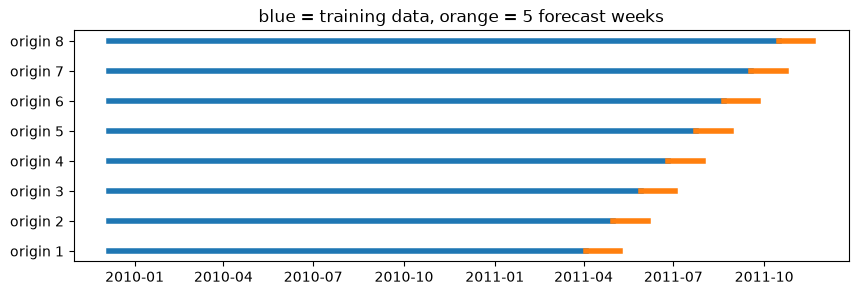

In [8]:
print("origins:", [d.date().isoformat() for d in ORIGINS])
fig, ax = plt.subplots(figsize=(10, 3))
for i, o in enumerate(ORIGINS):
    ax.plot([weekly.index[0], o], [i, i], color="tab:blue", linewidth=4)
    ax.plot([o, o + pd.Timedelta(weeks=H)], [i, i], color="tab:orange", linewidth=4)
ax.set_yticks(range(len(ORIGINS))); ax.set_yticklabels([f"origin {i+1}" for i in range(len(ORIGINS))])
ax.set_title("blue = training data, orange = 5 forecast weeks"); plt.show()

In [9]:
results = {name: backtest(fn)["MAE"] for name, fn in
           [("naive", naive), ("mean", mean_fc), ("seasonal naive", seasonal_naive), ("drift", drift)]}
per_origin = pd.DataFrame(results).set_axis([o.date() for o in ORIGINS])
(per_origin / 1000).round(1)

,naive,mean,seasonal naive,drift
2011-04-03,28.6,36.7,29.9,24.8
2011-05-01,77.5,28.8,22.9,84.0
2011-05-29,36.3,36.9,25.2,35.1
2011-06-26,26.8,23.2,27.0,31.2
2011-07-24,11.6,9.5,16.1,10.6
2011-08-21,51.6,54.6,41.3,52.3
2011-09-18,50.8,101.5,75.2,51.0
2011-10-16,54.4,104.0,21.9,55.3


In [10]:
summary = pd.DataFrame({"mean MAE £": per_origin.mean(), "worst origin £": per_origin.max(),
                        "times best": (per_origin.idxmin(axis=1).value_counts()
                                       .reindex(per_origin.columns).fillna(0).astype(int))})
summary.sort_values("mean MAE £").round(0)

,mean MAE £,worst origin £,times best
seasonal naive,32450.0,75249.0,4
naive,42200.0,77487.0,1
drift,43037.0,84013.0,1
mean,49412.0,104027.0,2


Seasonal naive has the lowest average error. Last week (naive) and drift are hurt every time the season turns, and the long-run mean is the worst: it ignores both recent level and season.

This table is the **bar to beat**. Every model in lessons 07.3 to 07.5 goes through exactly the same backtest, and if it cannot beat seasonal naive, it is not worth the complexity.

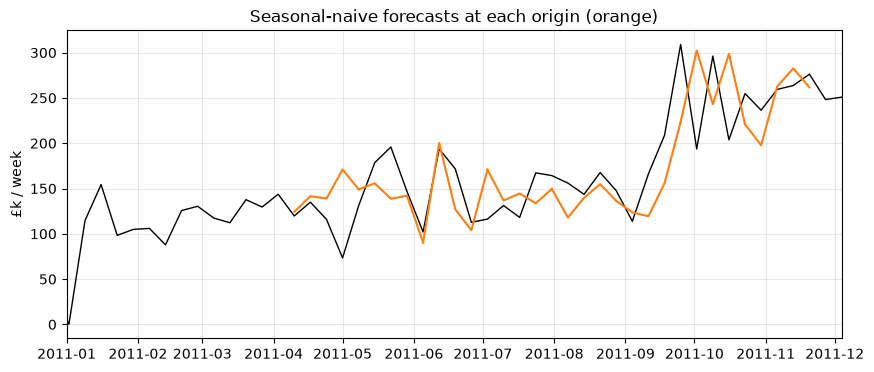

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly / 1000, color="black", linewidth=1, label="actual")
for o in ORIGINS:
    tr = weekly[weekly.index <= o]
    idx = weekly.index[weekly.index > o][:H]
    plt.plot(idx, seasonal_naive(tr, len(idx)) / 1000, color="tab:orange")
plt.xlim(pd.Timestamp("2011-01-01"), weekly.index[-1]); plt.ylabel("£k / week")
plt.title("Seasonal-naive forecasts at each origin (orange)"); plt.grid(alpha=.3); plt.show()

## Quiz answers

1. Seasonal naive: copy the value from one season ago. For weekly ShopWave data that is the same week last year.
2. MAE is in the target's units (pounds), easy to explain, and never explodes. MAPE divides by the actual value, so tiny or zero weeks blow it up.
3. Seasonal naive would forecast 20 for week 11 (the value four weeks earlier, week 7).
4. A single split gives one noisy score; the ranking can depend on which 5 weeks you happened to pick. Backtesting averages over many origins.
5. No. Every training window must end at its origin, so the model only ever sees the past.

**Next:** [07.3 Smoothing and Holt-Winters](../03-smoothing-holt-winters/)